# 19 — Skenario 4 (S4): S3 + Optimasi Hyperparameter dengan Optuna

**Dataset:** ABIDE I + ABIDE II (turunan DCAN), 1.638 subjek, 34 situs
**Modalitas:** rs-fMRI + sMRI + fenotipik (sama dengan S3)
**Model:** model usulan S3 (cabang graf GATv2 + cabang linear + cabang fenotipik, fusi atensi). Yang berubah **hanya hyperparameter**, yang sekarang dicari dengan **Optuna**

| | |
| :--- | :--- |
| **Masukan** | sama dengan notebook 18 (S3): `data/processed/kohort_dcan.csv` (notebook 09) · FC tangent 3 atlas per fold dan FC korelasi HCP (notebook 10/11) · morfometri 360 parcel × 5 (notebook 12/13) · fenotipik usia, jenis kelamin, FIQ (`kohort_dcan.csv`) · probabilitas baseline LR `result/tabel/22_cache/` (notebook 14) · prediksi S3 `result/tabel/27_S3_prediksi.csv` (notebook 18) |
| **Keluaran** | `result/tabel/29_optuna/fold<k>.db` (riwayat pencarian) · `result/tabel/29_S4_*.csv` · `result/metrics/S4_ringkasan.json` · `result/figure/29_*.png` · cache pelatihan `result/tabel/29_cache_5run/` |

> Berkas hasil memakai awalan **29**, lanjutan dari awalan berkas S1–S3 (25–27); awalan 28 dipakai S4 lama yang sudah diarsipkan. Awalan 20 sudah dipakai oleh berkas lama kurva belajar (arsip).

---

## Posisi S4 dalam rangkaian skenario

| Skenario | Notebook | Informasi yang dipakai | Hyperparameter |
| :---: | :---: | :--- | :--- |
| S1 | 16 | rs-fMRI | ditetapkan sebelum pelatihan |
| S2 | 17 | S1 + sMRI | sama |
| S3 | 18 | S2 + fenotipik (metode usulan) | sama |
| **S4** | **19 (ini)** | **sama dengan S3** | **dicari dengan Optuna di setiap fold** |

**Pertanyaan S4:** apakah model S3 bisa lebih baik bila hyperparameter-nya dioptimasi, bukan ditetapkan di awal?

S4 dibangun dari S3, karena S3 adalah metode usulan dengan AUC validasi tertinggi di antara S1–S3. Data, fitur, graf, fold, dan arsitektur **sama persis** dengan S3, sehingga selisih S4 − S3 bisa dibaca sebagai sumbangan optimasi hyperparameter.

---

## Apa itu Optuna, dan bagaimana dipakai di sini

**Optuna** adalah pustaka untuk mencari kombinasi hyperparameter secara otomatis. Setiap percobaan (*trial*) melatih satu model dengan satu kombinasi pengaturan, lalu menilainya. Optuna memakai **TPE** (*Tree-structured Parzen Estimator*), yang belajar dari trial sebelumnya kombinasi mana yang menjanjikan, sehingga pencarian lebih efisien daripada mencoba acak.

### Protokol: nested, supaya data uji tidak bocor

```
untuk setiap fold luar k (0–4):
    data latih fold k ──► dibagi: latih-dalam (85%) + validasi-tuning (15%, bertingkat situs × diagnosis)
    20 trial Optuna   ──► setiap trial: latih di latih-dalam, nilai AUC di validasi-tuning
    pengaturan terbaik fold k
    pelatihan akhir   ──► 5 seed dengan pengaturan terbaik, uji di data uji fold k (baru di sini data uji dipakai)
```

| Langkah | Dihitung dari |
| :--- | :--- |
| Acuan tangent, standardisasi fitur, PCA cabang linear, isian FIQ kosong | data latih setiap fold (sama dengan S3) |
| Pencarian Optuna | latih-dalam + validasi-tuning, **keduanya bagian dari data latih fold itu** |
| *Early stopping* pelatihan akhir | potongan validasi 15% dari data latih (sama dengan S3) |
| Data uji fold | **hanya** untuk evaluasi akhir; tidak pernah dilihat Optuna |

Setiap fold boleh mendapat pengaturan yang berbeda. Ini wajar, karena pencarian di setiap fold hanya melihat data latihnya sendiri. Kelima pengaturan dilaporkan di bagian 7.

### Ruang pencarian

| Hyperparameter | S3 (trial 0) | Rentang pencarian |
| :--- | :---: | :--- |
| Dimensi tersembunyi | 64 | 32 / 64 / 128 |
| Lapis GATv2 | 2 | 1 / 2 / 3 |
| *Attention head* | 4 | 2 / 4 |
| Dropout umum | 0,5 | 0,2 – 0,6 |
| Dropout input simpul | 0,2 | 0,0 – 0,4 |
| *DropEdge* (sisi) | 0,2 | 0,0 – 0,4 |
| Dropout cabang linear | 0,2 | 0,0 – 0,5 |
| Bobot loss kepala bantu | 0,5 | 0,1 – 1,0 |
| *Learning rate* | 10⁻³ | 2·10⁻⁴ – 3·10⁻³ (skala log) |
| *Weight decay* | 10⁻³ | 10⁻⁵ – 10⁻² (skala log) |
| *Batch size* | 32 | 16 / 32 / 64 |

Yang **tidak** dicari: jumlah tetangga graf (k = 20), epoch maksimum (200), *patience* (40), dan fitur. Fitur dan graf sengaja dibuat sama dengan S3 supaya yang berubah hanya hyperparameter.

- **Trial 0 selalu pengaturan S3.** Jadi pengaturan terbaik minimal sama baiknya dengan S3 pada validasi-tuning.
- **Penghentian dini (*MedianPruner*)**: mulai trial ke-6, trial yang AUC validasinya di bawah median trial lain pada epoch yang sama dihentikan lebih awal, supaya waktu tidak terbuang.

### Ekspektasi yang jujur

- Optuna **tidak menjamin** akurasi uji naik. Pengaturan yang terbaik di validasi-tuning (±200 subjek) bisa saja hanya cocok dengan potongan itu (*overfitting* ke validasi).
- Karena hyperparameter S4 dipilih memakai AUC validasi, **AUC validasi S4 cenderung lebih tinggi daripada aslinya** dibanding S1–S3. Perbandingan S4 dengan skenario lain sebaiknya dibaca dari **data uji** (bagian 8), bukan dari AUC validasi.

## Lama proses

- Pencarian: 5 fold × 20 trial, ±3–4 menit per trial (lebih cepat untuk trial yang dihentikan dini), jadi **±5–6 jam**.
- Pelatihan akhir: 5 fold × 5 seed, **±1,5 jam**.

Tutup kernel notebook lain sebelum menjalankan (penyiapan fitur memakai RAM ±3–4 GB). Setiap trial langsung tersimpan di `29_optuna/fold<k>.db` dan setiap fold pelatihan akhir di `29_cache_5run/`, jadi kalau terhenti cukup jalankan ulang sel yang sama. Trial yang sudah selesai akan dilewati.

> Kalau `N_TRIAL` atau ruang pencarian diubah setelah pelatihan akhir selesai, hapus folder `29_cache_5run/` supaya pelatihan akhir diulang dengan pengaturan baru.

## 1. Persiapan

In [1]:
import gc
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import importlib
import src.usulan
importlib.reload(src.usulan)          # selalu pakai versi terbaru src/usulan.py walau kernel belum di-restart
import src.optuna_usulan
importlib.reload(src.optuna_usulan)
import optuna
from src.metrics import hitung_metrik
from src.usulan import (DEVICE, ModelUsulan, buat_graf, fitur_linear_pca, fitur_simpul_baris, jalankan_cv_usulan, sisi_topk)
from src.optuna_usulan import HIPER_S3, RUANG, cari_hiper_fold, pisah_hiper

# ----- Parameter skenario (ditetapkan sebelum pelatihan) -----
SKENARIO = "S4"
ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}   # jumlah ROI setiap atlas DCAN
ATLAS_GRAF = "hcp2016"
N_SIMPUL = 360                     # parcel korteks HCP (berada di urutan awal time series DCAN)
K_SISI = 20                        # setiap simpul dihubungkan ke 20 tetangga dengan |korelasi| terbesar
# lr, weight_decay, batch_size, dan hyperparameter model diganti hasil Optuna setiap fold (bagian 7)
CFG_LATIH = dict(lr=1e-3, weight_decay=1e-3, batch_size=32, max_epochs=200, min_epochs=20, patience=40, val_size=0.15, seeds=(0, 1, 2, 3, 4))          # 5 seed = 5 run
N_TRIAL = 20                       # jumlah trial Optuna per fold (trial 0 = pengaturan S3)

PROC = ROOT / "data" / "processed"
FITUR_22 = PROC / "fitur_dcan_22"
CACHE_22 = ROOT / "result" / "tabel" / "22_cache"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
METRIK_DIR = ROOT / "result" / "metrics"
CACHE_DIR = TABEL_DIR / "29_cache_5run"      # awalan 29 = lanjutan berkas hasil S1–S3 (25–27); 28 = S4 lama (arsip)
OPTUNA_DIR = TABEL_DIR / "29_optuna"         # satu database SQLite per fold, supaya pencarian bisa dilanjutkan
for d in (TABEL_DIR, FIG_DIR, METRIK_DIR, CACHE_DIR, OPTUNA_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
fold = kohort["fold_gabungan"].to_numpy()
situs = kohort["situs"].to_numpy()
dataset = kohort["dataset"].to_numpy()
F_SMRI = np.load(PROC / "fitur_smri_dcan" / "fitur_smri_dcan.npz", allow_pickle=True)
NAMA_PARCEL = F_SMRI["parcel_hcp2016"].astype(str)
print(f"Perangkat: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

ringkas_data = (kohort.assign(ASD=y, Kontrol=1 - y)
                .groupby("dataset").agg(Subjek=("label", "size"), ASD=("ASD", "sum"), Kontrol=("Kontrol", "sum"), Situs=("situs", "nunique"),
                                        **{"Usia rata-rata": ("usia", "mean")}))
ringkas_data.loc["Total"] = [len(kohort), y.sum(), (1 - y).sum(), kohort["situs"].nunique(), kohort["usia"].mean()]
ringkas_data.index = ringkas_data.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II", "Total": "Total"})
display(ringkas_data.round(1).style.set_caption("Kohort ABIDE I + II (DCAN)"))

Perangkat: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


,Subjek,ASD,Kontrol,Situs,Usia rata-rata
dataset,,,,,
ABIDE I,886.000000,405.000000,481.000000,20.000000,16.900000
ABIDE II,752.000000,309.000000,443.000000,14.000000,15.300000
Total,1638.000000,714.000000,924.000000,34.000000,16.100000


## 2. Pembagian Fold

Fold sama dengan baseline LR (notebook 14) dan S1–S3 (notebook 16–18), sehingga hasil S4 bisa dibandingkan langsung (uji McNemar per subjek) dengan S3 dan baseline Logistic Regression.

In [2]:
tab_fold = pd.DataFrame({"Subjek uji": pd.Series(fold).value_counts().sort_index(),
                         "ASD (%)": pd.Series(y).groupby(fold).mean() * 100,
                         "ABIDE I": pd.Series(dataset == "abide1").groupby(fold).sum(),
                         "ABIDE II": pd.Series(dataset == "abide2").groupby(fold).sum(),
                         "Situs": pd.Series(situs).groupby(fold).nunique()})
tab_fold.index.name = "Fold"
display(tab_fold.round(1).style.set_caption("Isi setiap fold (data uji); data latih = empat fold lainnya"))

,Subjek uji,ASD (%),ABIDE I,ABIDE II,Situs
Fold,,,,,
0,328,44.500000,177,151,34
1,323,44.600000,172,151,34
2,335,44.200000,185,150,33
3,327,42.200000,177,150,33
4,325,42.500000,175,150,33


## 3. Graf Otak, Fitur sMRI, dan Fitur Fenotipik (sama dengan S3)

Bagian ini **sama persis** dengan notebook 18 bagian 3–5:
- **graf**: 360 parcel korteks HCP, setiap parcel dihubungkan ke 20 parcel dengan |korelasi| (Fisher z) terbesar;
- **morfometri**: 5 fitur per parcel, luas dan volume menjadi proporsi terhadap total subjek;
- **fenotipik**: log usia, jenis kelamin, FIQ (kosong diisi median data latih), dan penanda FIQ kosong;
- **fitur simpul** 360 × 384 dan **cabang linear** skor PCA FC tangent 3 atlas, distandardisasi dengan statistik data latih setiap fold.

Penjelasan dan gambar setiap langkah ada di notebook 18, jadi di sini hanya dijalankan ulang tanpa gambar.

In [3]:
t0 = time.perf_counter()
KORELASI = np.load(FITUR_22 / f"korelasi_{ATLAS_GRAF}.npy", mmap_mode="r")
SISI = sisi_topk(KORELASI, ATLAS[ATLAS_GRAF], N_SIMPUL, K_SISI)
n_sisi = np.array([s[0].shape[1] // 2 for s in SISI])
derajat0 = np.bincount(SISI[0][0][0].numpy(), minlength=N_SIMPUL)
print(f"Sisi graf siap untuk {len(SISI)} subjek ({time.perf_counter() - t0:.0f} detik)")
display(pd.DataFrame({"Simpul per graf": [N_SIMPUL], "Sisi tak berarah per graf (rata-rata)": [n_sisi.mean().round(0)],
                      "Kepadatan graf (%)": [(n_sisi.mean() / (N_SIMPUL * (N_SIMPUL - 1) / 2) * 100).round(2)],
                      "Derajat minimum (subjek pertama)": [derajat0.min()], "Simpul terisolasi": [int((derajat0 == 0).sum())]}))

Sisi graf siap untuk 1638 subjek (13 detik)


,Simpul per graf,Sisi tak berarah per graf (rata-rata),Kepadatan graf (%),Derajat minimum (subjek pertama),Simpul terisolasi
0,360,5129.0,7.94,20,0


In [4]:
def morfo_relatif(M):
    """(N, R, 5): luas & volume -> proporsi terhadap total subjek; ketebalan, kelengkungan, sulkus apa adanya."""
    M = M.astype(np.float64).copy()
    M[:, :, 0] /= M[:, :, 0].sum(1, keepdims=True)
    M[:, :, 1] /= M[:, :, 1].sum(1, keepdims=True)
    return M.astype(np.float32)

def standar_latih(X, idx_latih):
    """Standardisasi per (parcel, fitur) / per kolom dengan statistik data latih."""
    mu = X[idx_latih].mean(0, keepdims=True)
    sd = X[idx_latih].std(0, keepdims=True) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

assert list(F_SMRI["sub"]) == list(kohort["sub"]), "urutan subjek sMRI tidak sama dengan kohort"
MORFO = morfo_relatif(F_SMRI["morfo_hcp2016"])               # (N, 360, 5)
assert MORFO.shape == (len(kohort), N_SIMPUL, 5) and np.isfinite(MORFO).all()
print("Morfometri:", MORFO.shape)

Morfometri: (1638, 360, 5)


In [5]:
FIQ_KOSONG = kohort["fiq"].isna().to_numpy()
FEN_MENTAH = np.column_stack([np.log(kohort["usia"].to_numpy(float)), (kohort["jenis_kelamin"] == 2).to_numpy(float),
                              kohort["fiq"].to_numpy(float), FIQ_KOSONG.astype(float)])
NAMA_FEN = ["log usia", "perempuan", "FIQ", "FIQ kosong"]

def fitur_fenotipik(idx_latih):
    """(N, 4): FIQ kosong diisi median data latih; log usia dan FIQ distandardisasi dengan statistik data latih."""
    X = FEN_MENTAH.copy()
    X[FIQ_KOSONG, 2] = np.nanmedian(X[idx_latih, 2])
    for j in (0, 2):
        X[:, j] = (X[:, j] - X[idx_latih, j].mean()) / (X[idx_latih, j].std() + 1e-6)
    return X.astype(np.float32)

print("Fitur fenotipik:", NAMA_FEN, "| FIQ kosong:", int(FIQ_KOSONG.sum()), "subjek")

Fitur fenotipik: ['log usia', 'perempuan', 'FIQ', 'FIQ kosong'] | FIQ kosong: 129 subjek


In [6]:
_simpan = {}

def siapkan_fold(k, idx_latih_penuh):
    """Data PyG untuk SEMUA subjek pada fold k; statistik fitur hanya dari idx_latih_penuh."""
    if _simpan.get("fold") == k:
        return _simpan["data"]
    _simpan.clear()
    gc.collect()                       # lepaskan fitur fold sebelumnya (±1 GB) sebelum membuat yang baru
    V = {a: np.load(FITUR_22 / f"tangent_{a}_gab_{k}.npy", mmap_mode="r") for a in ATLAS}
    X_fc = fitur_simpul_baris(V[ATLAS_GRAF], ATLAS[ATLAS_GRAF], N_SIMPUL, idx_latih_penuh)              # (N, 360, 379)
    X_simpul = np.concatenate([X_fc, standar_latih(MORFO, idx_latih_penuh)], axis=2)                    # (N, 360, 384)
    del X_fc
    X_linear = fitur_linear_pca([V[a] for a in ATLAS], idx_latih_penuh)
    data = buat_graf(y, X_simpul, SISI, X_linear=X_linear, X_fenotipe=fitur_fenotipik(idx_latih_penuh))
    _simpan.update(fold=k, data=data, X_simpul=X_simpul, X_linear=X_linear)
    return data

t0 = time.perf_counter()
latih0 = np.where(fold != 0)[0]
data0 = siapkan_fold(0, latih0)
Xs, Xl = _simpan["X_simpul"], _simpan["X_linear"]
display(pd.DataFrame({
    "Fitur": ["simpul (cabang graf)", "linear (cabang linear)"],
    "Bentuk": [f"{Xs.shape[0]} × {Xs.shape[1]} × {Xs.shape[2]}", f"{Xl.shape[0]} × {Xl.shape[1]}"],
    "Rata-rata data latih": [float(Xs[latih0].mean()), float(Xl[latih0].mean())],
    "SD data latih": [float(Xs[latih0].std()), float(Xl[latih0].std())],
    "Nilai tidak finit": [int((~np.isfinite(Xs)).sum()), int((~np.isfinite(Xl)).sum())],
}).round(4).style.set_caption(f"Fitur fold 0 ({time.perf_counter() - t0:.0f} detik)"))
display(pd.DataFrame({"Bagian fitur simpul": ["FC tangent (kolom 0–378)", "morfometri (kolom 379–383)"],
                      "Rata-rata data latih": [float(Xs[latih0][:, :, :379].mean()), float(Xs[latih0][:, :, 379:].mean())],
                      "SD data latih": [float(Xs[latih0][:, :, :379].std()), float(Xs[latih0][:, :, 379:].std())]}).round(4))
display(pd.DataFrame(data0[0].x_fen.numpy(), columns=NAMA_FEN).round(3).style.set_caption("Contoh fitur fenotipik subjek pertama (sudah diolah)"))
print("Contoh satu objek graf:", data0[0])

,Fitur,Bentuk,Rata-rata data latih,SD data latih,Nilai tidak finit
0,simpul (cabang graf),1638 × 360 × 384,0.000000,0.998700,0
1,linear (cabang linear),1638 × 3927,-0.000000,0.027600,0


,Bagian fitur simpul,Rata-rata data latih,SD data latih
0,FC tangent (kolom 0–378),0.0,0.9987
1,morfometri (kolom 379–383),0.0,0.9985


,log usia,perempuan,FIQ,FIQ kosong
0,1.052000,0.000000,-0.192000,0.000000


Contoh satu objek graf: Data(x=[360, 384], edge_index=[2, 11108], edge_attr=[11108, 1], y=[1], x_lin=[1, 3927], x_fen=[1, 4])


## 4. Model dan Pemeriksaan Bentuk Tensor

`buat_model_hiper` membuat model S3 dengan hyperparameter model tertentu, dan dipakai Optuna untuk setiap trial. Pemeriksaan bentuk tensor di bawah memakai pengaturan S3.

In [7]:
def buat_model_hiper(contoh, hiper_model):
    """Model usulan S3 (3 cabang) dengan hyperparameter model tertentu."""
    return ModelUsulan(N_SIMPUL, d_simpul=contoh.x.size(1), d_linear=contoh.x_lin.size(1), d_fenotipe=contoh.x_fen.size(1), **hiper_model)

from torch_geometric.loader import DataLoader
model_cek = buat_model_hiper(data0[0], pisah_hiper(HIPER_S3)[0]).to(DEVICE).eval()   # dicek dengan pengaturan S3
b = next(iter(DataLoader(data0[:4], batch_size=4))).to(DEVICE)
with torch.no_grad():
    logit = model_cek(b)
display(pd.DataFrame([
    {"Tahap": "input fitur simpul (4 graf digabung)", "Bentuk": tuple(b.x.shape)},
    {"Tahap": "input sisi (edge_index)", "Bentuk": tuple(b.edge_index.shape)},
    {"Tahap": "input cabang linear", "Bentuk": tuple(b.x_lin.shape)},
    {"Tahap": "input cabang fenotipik", "Bentuk": tuple(b.x_fen.shape)},
    {"Tahap": "bobot atensi parcel α (per subjek)", "Bentuk": tuple(model_cek.alpha().shape)},
    {"Tahap": "bobot cabang β (graf, linear, fenotipik)", "Bentuk": tuple(model_cek.beta_terakhir.shape)},
    {"Tahap": "keluaran logits [Kontrol, ASD]", "Bentuk": tuple(logit.shape)},
]))
param = {n: sum(p.numel() for p in model_cek.cabang[n].parameters()) for n in model_cek.nama_cabang}
param["fusi + kepala"] = sum(p.numel() for p in model_cek.parameters()) - sum(param.values())
display(pd.DataFrame({"Bagian": list(param), "Jumlah parameter": list(param.values())}).style.set_caption(
    f"Total parameter dengan pengaturan S3: {sum(param.values()):,}"))
assert torch.allclose(model_cek.alpha().sum(1), torch.ones(4, device=DEVICE)), "α setiap subjek harus berjumlah 1"
del model_cek, b, data0, Xs, Xl      # nama-nama ini menahan fitur fold 0 (±1 GB) di memori; lepaskan sebelum pelatihan
gc.collect()

,Tahap,Bentuk
0,input fitur simpul (4 graf digabung),"(1440, 384)"
1,input sisi (edge_index),"(2, 42624)"
2,input cabang linear,"(4, 3927)"
3,input cabang fenotipik,"(4, 4)"
4,bobot atensi parcel α (per subjek),"(4, 360)"
5,"bobot cabang β (graf, linear, fenotipik)","(4, 3)"
6,"keluaran logits [Kontrol, ASD]","(4, 2)"


,Bagian,Jumlah parameter
0,graf,167813
1,linear,251392
2,fenotipik,4480
3,fusi + kepala,7177


108

## 5. Pencarian Hyperparameter dengan Optuna (per Fold)

Sel berikut adalah bagian terlama (±5–6 jam). Setiap baris log menunjukkan satu trial selesai: AUC validasi-tuning, atau "dihentikan awal" kalau trial itu dihentikan dini. Di akhir setiap fold dicetak AUC validasi terbaik dibanding trial 0 (pengaturan S3).

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
STUDY = {}
t0 = time.perf_counter()
for k in [int(v) for v in sorted(np.unique(fold))]:
    latih_penuh = np.where(fold != k)[0]
    data_k = siapkan_fold(k, latih_penuh)                  # statistik fitur hanya dari data latih fold k
    STUDY[k] = cari_hiper_fold(k, data_k, latih_penuh, y, situs, buat_model_hiper, N_TRIAL, OPTUNA_DIR / f"fold{k}.db", cfg_dasar=CFG_LATIH)
    del data_k
    print(f"  fold {k}: AUC val terbaik {STUDY[k].best_value * 100:.2f} (trial S3: {STUDY[k].trials[0].value * 100:.2f}) "
          f"| {(time.perf_counter() - t0) / 60:.0f} menit berjalan", flush=True)
_simpan.clear()
gc.collect()
print(f"\nPencarian selesai dalam {(time.perf_counter() - t0) / 60:.1f} menit (≈0 berarti semua trial dibaca dari database).")

    fold 0 trial  0: AUC val 79.73 | 2.6 menit | terbaik sejauh ini 79.73
    fold 0 trial  1: AUC val 77.43 | 3.4 menit | terbaik sejauh ini 79.73
    fold 0 trial  2: AUC val 80.14 | 2.5 menit | terbaik sejauh ini 80.14
    fold 0 trial  3: AUC val 83.75 | 3.1 menit | terbaik sejauh ini 83.75
    fold 0 trial  4: AUC val 80.29 | 9.7 menit | terbaik sejauh ini 83.75
    fold 0 trial  5: dihentikan awal | 0.7 menit | terbaik sejauh ini 83.75
    fold 0 trial  6: dihentikan awal | 0.6 menit | terbaik sejauh ini 83.75
    fold 0 trial  7: AUC val 81.70 | 2.1 menit | terbaik sejauh ini 83.75
    fold 0 trial  8: dihentikan awal | 8.8 menit | terbaik sejauh ini 83.75
    fold 0 trial  9: dihentikan awal | 1.1 menit | terbaik sejauh ini 83.75
    fold 0 trial 10: AUC val 83.49 | 2.6 menit | terbaik sejauh ini 83.75
    fold 0 trial 11: AUC val 82.86 | 3.3 menit | terbaik sejauh ini 83.75
    fold 0 trial 12: AUC val 84.82 | 2.7 menit | terbaik sejauh ini 84.82
    fold 0 trial 13: dihentika

### 5.1 Pengaturan terbaik setiap fold

Tabel di bawah membandingkan AUC validasi-tuning pengaturan S3 (trial 0) dengan pengaturan terbaik, beserta nilai setiap hyperparameter. Kalau trial terbaik adalah trial 0, artinya Optuna tidak menemukan pengaturan yang lebih baik daripada S3 di fold itu.

,AUC val S3 / trial 0 (%),AUC val terbaik (%),trial terbaik,selesai / dihentikan awal,hidden,n_layer,heads,dropout,dropout_input,dropedge,dropout_linear,bobot_bantu,lr,weight_decay,batch_size
fold,,,,,,,,,,,,,,,
0,79.7269,84.8214,12.0000,9 / 11,128,1,2,0.3879,0.3861,0.2321,0.0430,0.2865,0.0008,0.0038,32
1,87.2093,87.2093,0.0000,9 / 11,64,2,4,0.5000,0.2000,0.2000,0.2000,0.5000,0.0010,0.0010,32
2,76.5342,84.5151,16.0000,15 / 5,128,1,4,0.3871,0.1667,0.1686,0.2357,0.1585,0.0007,0.0002,32
3,72.9049,80.0470,7.0000,14 / 6,32,1,4,0.4561,0.0573,0.1657,0.0246,0.2884,0.0014,0.0009,64
4,64.6344,73.2925,15.0000,13 / 7,64,1,2,0.4843,0.3755,0.2930,0.2647,0.4596,0.0022,0.0001,64
S3 (acuan),–,–,–,–,64,2,4,0.5000,0.2000,0.2000,0.2000,0.5000,0.0010,0.0010,32


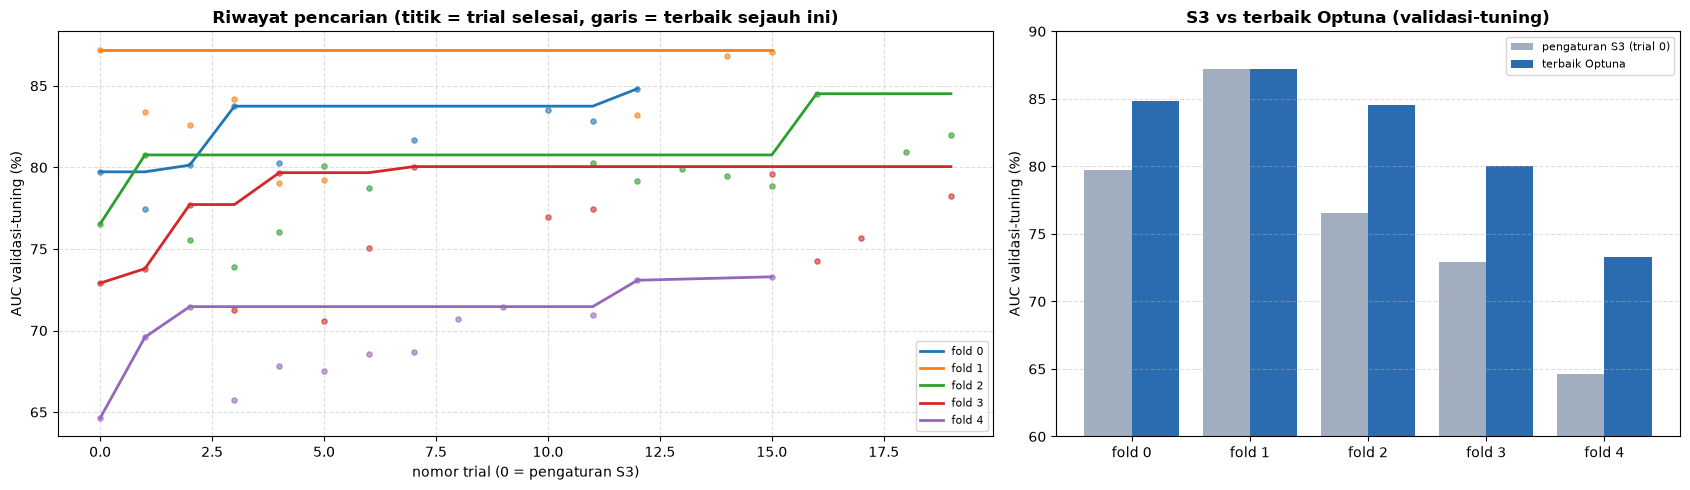

In [9]:
STATUS = optuna.trial.TrialState
baris = []
for k, st in STUDY.items():
    t = st.best_trial
    baris.append({"fold": k, "AUC val S3 / trial 0 (%)": st.trials[0].value * 100, "AUC val terbaik (%)": t.value * 100,
                  "trial terbaik": t.number,
                  "selesai / dihentikan awal": f"{sum(x.state == STATUS.COMPLETE for x in st.trials)} / {sum(x.state == STATUS.PRUNED for x in st.trials)}",
                  **t.params})
tab_optuna = pd.DataFrame(baris).set_index("fold")
tab_optuna.loc["S3 (acuan)"] = {**{c: np.nan for c in tab_optuna.columns}, **HIPER_S3}
display(tab_optuna.style.format(precision=4, na_rep="–").set_caption("Hasil Optuna per fold"))
tab_optuna.to_csv(TABEL_DIR / "29_S4_optuna_terbaik.csv")
pd.concat([st.trials_dataframe().assign(fold=k) for k, st in STUDY.items()]).to_csv(TABEL_DIR / "29_S4_optuna_semua_trial.csv", index=False)

HIPER_FOLD = {k: pisah_hiper(st.best_params)[0] for k, st in STUDY.items()}     # untuk ModelUsulan
CFG_FOLD = {k: {**pisah_hiper(st.best_params)[1]} for k, st in STUDY.items()}   # lr, weight_decay, batch_size

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 1]})
for k, st in STUDY.items():
    sel = [t for t in st.trials if t.state == STATUS.COMPLETE]
    no, nilai = [t.number for t in sel], [t.value * 100 for t in sel]
    garis = axes[0].plot(no, np.maximum.accumulate(nilai), lw=2, label=f"fold {k}")[0]
    axes[0].scatter(no, nilai, s=14, color=garis.get_color(), alpha=0.6)
axes[0].set_xlabel("nomor trial (0 = pengaturan S3)"); axes[0].set_ylabel("AUC validasi-tuning (%)")
axes[0].set_title("Riwayat pencarian (titik = trial selesai, garis = terbaik sejauh ini)", fontweight="bold")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.4, ls="--")
x = np.arange(len(STUDY))
axes[1].bar(x - 0.2, tab_optuna.iloc[:len(STUDY)]["AUC val S3 / trial 0 (%)"], 0.4, color="#A0AEC0", label="pengaturan S3 (trial 0)")
axes[1].bar(x + 0.2, tab_optuna.iloc[:len(STUDY)]["AUC val terbaik (%)"], 0.4, color="#2B6CB0", label="terbaik Optuna")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"fold {k}" for k in STUDY]); axes[1].set_ylim(60, 90)
axes[1].set_ylabel("AUC validasi-tuning (%)"); axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=0.4, ls="--")
axes[1].set_title("S3 vs terbaik Optuna (validasi-tuning)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "29_1_optuna_riwayat.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Pelatihan Akhir 5-Fold dengan Pengaturan Terbaik

Setiap fold dilatih ulang dengan pengaturan terbaiknya, memakai **5 seed (5 run)** seperti S1–S3. Data latih, potongan validasi untuk *early stopping*, dan seed sama dengan S3, sehingga run ke-r S4 bisa dibandingkan berpasangan dengan run ke-r S3. Yang berbeda hanya hyperparameter.

In [10]:
def buat_model(contoh, k):
    return buat_model_hiper(contoh, HIPER_FOLD[k])

t0 = time.perf_counter()
HASIL = jalankan_cv_usulan(y, situs, fold, siapkan_fold, buat_model, cfg=CFG_LATIH, cache_dir=CACHE_DIR, cfg_fold=CFG_FOLD)
_simpan.clear()
print(f"\nSelesai dalam {(time.perf_counter() - t0) / 60:.1f} menit (≈0 berarti semua fold dibaca dari cache).")

    fold 0 seed 0: epoch terbaik 144 | AUC val 73.18 | 7.5 menit
    fold 0 seed 1: epoch terbaik  65 | AUC val 76.87 | 4.4 menit
    fold 0 seed 2: epoch terbaik  71 | AUC val 78.83 | 4.6 menit
    fold 0 seed 3: epoch terbaik  68 | AUC val 77.08 | 4.5 menit
    fold 0 seed 4: epoch terbaik  28 | AUC val 80.51 | 2.9 menit
  fold 0: ACC 74.09 | AUC 81.14 (24 menit berjalan)
    fold 1 seed 0: epoch terbaik  22 | AUC val 73.60 | 3.1 menit
    fold 1 seed 1: epoch terbaik  31 | AUC val 75.12 | 3.6 menit
    fold 1 seed 2: epoch terbaik  21 | AUC val 73.61 | 3.1 menit
    fold 1 seed 3: epoch terbaik  26 | AUC val 72.30 | 3.4 menit
    fold 1 seed 4: epoch terbaik  38 | AUC val 75.81 | 4.0 menit
  fold 1: ACC 69.35 | AUC 77.59 (42 menit berjalan)
    fold 2 seed 0: epoch terbaik  24 | AUC val 78.72 | 3.4 menit
    fold 2 seed 1: epoch terbaik  49 | AUC val 76.87 | 4.6 menit
    fold 2 seed 2: epoch terbaik  42 | AUC val 80.07 | 4.3 menit
    fold 2 seed 3: epoch terbaik  20 | AUC val 73.9

## 7. Hasil

### 7.1 Hasil 5 run

Setiap baris adalah satu validasi silang 5-fold lengkap dengan seed berbeda. Metrik setiap run = rata-rata 5 fold. Baris terakhir adalah **hasil utama S4**: rata-rata ± SD antar run.

In [11]:
P_LR = np.mean([np.load(CACHE_22 / f"C3_gab_tangent_{a}.npz")["p"] for a in ATLAS], axis=0)
N_RUN = HASIL["p_run"].shape[1]
KOLOM = {"accuracy": "Akurasi", "balanced": "Balanced acc.", "sensitivity": "Sensitivitas", "specificity": "Spesifisitas",
         "precision": "Presisi", "f1": "F1", "auc": "AUC"}

def metrik_per_fold(p):
    df = pd.DataFrame([{"fold": k, **hitung_metrik(y[fold == k], p[fold == k])} for k in sorted(np.unique(fold))])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return df

def rata_fold(p):
    return metrik_per_fold(p)[list(KOLOM)].mean() * 100

tab_run = pd.DataFrame([rata_fold(HASIL["p_run"][:, r]) for r in range(N_RUN)], index=[f"run {r + 1} (seed {r})" for r in range(N_RUN)])
tab_run.columns = [f"{KOLOM[k]} (%)" for k in tab_run.columns]
tab_run_tampil = tab_run.round(2).astype(str)
tab_run_tampil.loc["Rata-rata ± SD antar run"] = [f"{m:.2f} ± {s:.2f}" for m, s in zip(tab_run.mean(), tab_run.std(ddof=1))]
display(tab_run_tampil.style.set_caption(f"S4: {N_RUN} run × 5-fold (1.638 subjek)"))
tab_run_tampil.to_csv(TABEL_DIR / "29_S4_per_run.csv")

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
run 1 (seed 0),74.91,73.71,64.46,82.97,75.31,69.11,80.62
run 2 (seed 1),71.48,69.78,55.97,83.58,72.35,62.72,79.52
run 3 (seed 2),73.32,72.2,63.14,81.27,72.37,67.24,80.84
run 4 (seed 3),71.53,69.83,56.59,83.07,73.12,63.2,80.06
run 5 (seed 4),72.29,71.09,61.71,80.47,71.1,65.91,79.9
Rata-rata ± SD antar run,72.70 ± 1.44,71.32 ± 1.67,60.37 ± 3.87,82.27 ± 1.33,72.85 ± 1.55,65.63 ± 2.70,80.19 ± 0.54


### 7.2 Perbandingan dengan baseline

| Baris | Arti | SD |
| :--- | :--- | :--- |
| **S4 model usulan (5 run)** | hasil utama | antar run |
| S4 ensemble 5 run | probabilitas kelima run dirata-rata | antar fold |
| kepala bantu: cabang graf / linear / fenotipik | prediksi kepala bantu satu cabang pada model yang sama (ensemble 5 run), **bukan** model terpisah | antar fold |
| Baseline LR (notebook 10) | FC tangent 3 atlas, subjek dan fold sama. Penjelasan di notebook 14; label "notebook 22" adalah nomor lama notebook 10 | antar fold |

In [12]:
PRED = {"S4 ensemble 5 run": HASIL["p"], "  kepala bantu: cabang graf": HASIL["p_graf"],
        "  kepala bantu: cabang linear": HASIL["p_linear"], "  kepala bantu: cabang fenotipik": HASIL["p_fenotipik"],
        "Baseline LR (notebook 22)": P_LR}

def ringkas_fold(p):
    df = metrik_per_fold(p)
    return {f"{v} (%)": f"{df[k].mean() * 100:.2f} ± {df[k].std(ddof=0) * 100:.2f}" for k, v in KOLOM.items()}

tab_hasil = pd.DataFrame({"S4 model usulan (5 run)": tab_run_tampil.loc["Rata-rata ± SD antar run"].to_dict(),
                          **{n: ringkas_fold(p) for n, p in PRED.items()}}).T
display(tab_hasil.style.set_caption("S4 vs baseline"))

per_fold = metrik_per_fold(HASIL["p"]).set_index("fold")[list(KOLOM)] * 100
per_fold["LR akurasi"] = metrik_per_fold(P_LR).set_index("fold")["accuracy"] * 100
display(per_fold.round(2).style.set_caption("S4 ensemble per fold (%)"))

tab_hasil.to_csv(TABEL_DIR / "29_S4_ringkasan.csv")
per_fold.to_csv(TABEL_DIR / "29_S4_per_fold.csv")
pd.DataFrame({"FILE_ID": kohort["FILE_ID"], "dataset": dataset, "situs": situs, "fold": fold, "y_true": y,
              "p_ensemble": HASIL["p"], **{f"p_run{r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)},
              "p_graf": HASIL["p_graf"], "p_linear": HASIL["p_linear"], "p_fenotipik": HASIL["p_fenotipik"], "p_lr": P_LR}).to_csv(TABEL_DIR / "29_S4_prediksi.csv", index=False)
with open(METRIK_DIR / "S4_ringkasan.json", "w", encoding="utf-8") as f:
    json.dump({"skenario": SKENARIO, "notebook": "19", "n_subjek": int(len(y)), "n_run": int(N_RUN),
               "rata_rata_antar_run": tab_run.mean().round(4).to_dict(), "sd_antar_run": tab_run.std(ddof=1).round(4).to_dict(),
               "per_run": tab_run.round(4).to_dict(orient="index"), "ensemble": rata_fold(HASIL["p"]).round(4).to_dict(),
               "hiper_model_per_fold": {int(k): v for k, v in HIPER_FOLD.items()}, "latih_per_fold": {int(k): v for k, v in CFG_FOLD.items()},
               "n_trial_optuna": N_TRIAL, "cfg_latih": {k: list(v) if isinstance(v, tuple) else v for k, v in CFG_LATIH.items()},
               "k_sisi": K_SISI, "fusi": "fusi atensi"}, f, indent=2)

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
S4 model usulan (5 run),72.70 ± 1.44,71.32 ± 1.67,60.37 ± 3.87,82.27 ± 1.33,72.85 ± 1.55,65.63 ± 2.70,80.19 ± 0.54
S4 ensemble 5 run,73.68 ± 2.31,72.21 ± 2.11,60.68 ± 3.70,83.74 ± 3.73,74.53 ± 4.11,66.77 ± 2.42,81.12 ± 2.23
kepala bantu: cabang graf,69.56 ± 4.39,68.51 ± 4.43,60.41 ± 5.62,76.60 ± 4.50,66.69 ± 5.79,63.34 ± 5.37,75.68 ± 4.26
kepala bantu: cabang linear,73.07 ± 1.81,71.56 ± 1.75,59.70 ± 3.63,83.41 ± 2.49,73.67 ± 2.47,65.87 ± 2.20,80.97 ± 1.72
kepala bantu: cabang fenotipik,61.92 ± 1.29,60.43 ± 1.44,47.95 ± 8.06,72.91 ± 6.62,58.06 ± 3.13,52.00 ± 3.63,65.73 ± 2.56
Baseline LR (notebook 22),73.23 ± 3.48,71.83 ± 3.48,61.14 ± 5.65,82.52 ± 3.84,73.18 ± 4.59,66.50 ± 4.52,81.35 ± 2.14


,accuracy,balanced,sensitivity,specificity,precision,f1,auc,LR akurasi
fold,,,,,,,,
0,74.090000,72.990000,63.010000,82.970000,74.800000,68.400000,81.140000,72.260000
1,69.350000,68.070000,56.250000,79.890000,69.230000,62.070000,77.590000,67.180000
2,74.330000,72.710000,58.780000,86.630000,77.680000,66.920000,82.690000,77.310000
3,74.310000,73.280000,66.670000,79.890000,70.770000,68.660000,80.100000,73.700000
4,76.310000,74.000000,58.700000,89.300000,80.200000,67.780000,84.100000,75.690000


### 7.3 Uji kebermaknaan terhadap baseline

Uji McNemar membandingkan prediksi benar/salah **per subjek** antara dua model pada subjek uji yang sama. Setiap run diuji terhadap LR, ditambah ensemble dan kepala bantu setiap cabang. Nilai p dikoreksi dengan metode Holm.

In [13]:
def mcnemar(pa, pb):
    A, B = (pa >= 0.5).astype(int) == y, (pb >= 0.5).astype(int) == y
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"Selisih akurasi (poin)": round((B.mean() - A.mean()) * 100, 2), "Hanya benar di model": n01, "Hanya benar di LR": n10,
            "p": stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0}

UJI = {**{f"S4 run {r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)}, **{n: p for n, p in PRED.items() if not n.startswith("Baseline")}}
uji = pd.DataFrame([{"Model (dibanding baseline LR)": n.strip(), **mcnemar(P_LR, p)} for n, p in UJI.items()])
urut = np.argsort(uji["p"].to_numpy())
holm = np.minimum(1, np.maximum.accumulate(uji["p"].to_numpy()[urut] * (len(uji) - np.arange(len(uji)))))
uji.loc[uji.index[urut], "p Holm"] = holm
uji["Kesimpulan"] = np.where(uji["p Holm"] >= 0.05, "setara (tidak berbeda bermakna)",
                             np.where(uji["Selisih akurasi (poin)"] > 0, "lebih baik secara bermakna", "lebih rendah secara bermakna"))
display(uji.round(4).style.set_caption("Uji McNemar + koreksi Holm"))
uji.to_csv(TABEL_DIR / "29_S4_uji_mcnemar.csv", index=False)

,Model (dibanding baseline LR),Selisih akurasi (poin),Hanya benar di model,Hanya benar di LR,p,p Holm,Kesimpulan
0,S4 run 1,1.650000,123,96,0.078700,0.393500,setara (tidak berbeda bermakna)
1,S4 run 2,-1.770000,93,122,0.055900,0.391500,setara (tidak berbeda bermakna)
2,S4 run 3,0.060000,91,90,1.000000,1.000000,setara (tidak berbeda bermakna)
3,S4 run 4,-1.710000,89,117,0.059700,0.391500,setara (tidak berbeda bermakna)
4,S4 run 5,-0.980000,98,114,0.302900,1.000000,setara (tidak berbeda bermakna)
5,S4 ensemble 5 run,0.430000,77,70,0.620800,1.000000,setara (tidak berbeda bermakna)
6,kepala bantu: cabang graf,-3.660000,129,189,0.000900,0.007300,lebih rendah secara bermakna
7,kepala bantu: cabang linear,-0.180000,50,53,0.843900,1.000000,setara (tidak berbeda bermakna)
8,kepala bantu: cabang fenotipik,-11.360000,237,423,0.000000,0.000000,lebih rendah secara bermakna


### 7.4 Perbandingan dengan S3: apakah Optuna menambah akurasi?

Ini pertanyaan utama S4. S3 dan S4 memakai fold, potongan validasi, dan seed yang sama, jadi **run ke-r di S4 dibandingkan dengan run ke-r di S3** (berpasangan):
- selisih akurasi dan AUC per run, beserta rata-ratanya;
- uji t berpasangan antar 5 run;
- uji McNemar per subjek antara ensemble S4 dan ensemble S3.

In [14]:
S3 = pd.read_csv(TABEL_DIR / "27_S3_prediksi.csv")
assert (S3["FILE_ID"].to_numpy() == kohort["FILE_ID"].to_numpy()).all(), "urutan subjek S3 dan S4 berbeda"
P1_RUN = S3[[f"p_run{r + 1}" for r in range(N_RUN)]].to_numpy()
banding = pd.DataFrame({"run": [f"run {r + 1}" for r in range(N_RUN)],
                        "Akurasi S3 (%)": [rata_fold(P1_RUN[:, r])["accuracy"] for r in range(N_RUN)],
                        "Akurasi S4 (%)": [rata_fold(HASIL["p_run"][:, r])["accuracy"] for r in range(N_RUN)],
                        "AUC S3 (%)": [rata_fold(P1_RUN[:, r])["auc"] for r in range(N_RUN)],
                        "AUC S4 (%)": [rata_fold(HASIL["p_run"][:, r])["auc"] for r in range(N_RUN)]})
banding["Selisih akurasi (S4 − S3)"] = banding["Akurasi S4 (%)"] - banding["Akurasi S3 (%)"]
banding["Selisih AUC (S4 − S3)"] = banding["AUC S4 (%)"] - banding["AUC S3 (%)"]
t_acc = stats.ttest_rel(banding["Akurasi S4 (%)"], banding["Akurasi S3 (%)"])
t_auc = stats.ttest_rel(banding["AUC S4 (%)"], banding["AUC S3 (%)"])
display(banding.round(2).style.set_caption(
    f"S4 vs S3 per run | rata-rata selisih akurasi {banding['Selisih akurasi (S4 − S3)'].mean():+.2f} poin (uji t berpasangan p = {t_acc.pvalue:.3f}), "
    f"AUC {banding['Selisih AUC (S4 − S3)'].mean():+.2f} poin (p = {t_auc.pvalue:.3f})"))

uji_s1 = pd.DataFrame([{"Perbandingan": "ensemble S3 → ensemble S4", **mcnemar(S3["p_ensemble"].to_numpy(), HASIL["p"])},
                       {"Perbandingan": "kepala bantu graf S3 → S4", **mcnemar(S3["p_graf"].to_numpy(), HASIL["p_graf"])}])
uji_s1 = uji_s1.rename(columns={"Hanya benar di model": "Hanya benar di S4", "Hanya benar di LR": "Hanya benar di S3"})
uji_s1["Bermakna (p < 0,05)"] = np.where(uji_s1["p"] < 0.05, "ya", "tidak")
display(uji_s1.round(4).style.set_caption("Uji McNemar S3 vs S4 (subjek sama)"))
banding.to_csv(TABEL_DIR / "29_S4_vs_S3_per_run.csv", index=False)
uji_s1.to_csv(TABEL_DIR / "29_S4_vs_S3_mcnemar.csv", index=False)

,run,Akurasi S3 (%),Akurasi S4 (%),AUC S3 (%),AUC S4 (%),Selisih akurasi (S4 − S3),Selisih AUC (S4 − S3)
0,run 1,71.960000,74.910000,79.630000,80.620000,2.950000,0.990000
1,run 2,70.860000,71.480000,78.970000,79.520000,0.620000,0.550000
2,run 3,71.730000,73.320000,78.970000,80.840000,1.590000,1.870000
3,run 4,72.940000,71.530000,80.050000,80.060000,-1.410000,0.010000
4,run 5,71.440000,72.290000,79.410000,79.900000,0.850000,0.490000


,Perbandingan,Selisih akurasi (poin),Hanya benar di S4,Hanya benar di S3,p,"Bermakna (p < 0,05)"
0,ensemble S3 → ensemble S4,0.310000,74,69,0.738100,tidak
1,kepala bantu graf S3 → S4,0.670000,170,159,0.581500,tidak


### 7.5 Grafik ringkasan

- **Kiri**: akurasi, balanced accuracy, dan AUC. Batang S4 = rata-rata 5 run (titik = setiap run); batang lain = ensemble/baseline (titik = setiap fold);
- **Tengah**: kurva ROC seluruh subjek uji;
- **Kanan**: confusion matrix S4 ensemble (ambang 0,5).

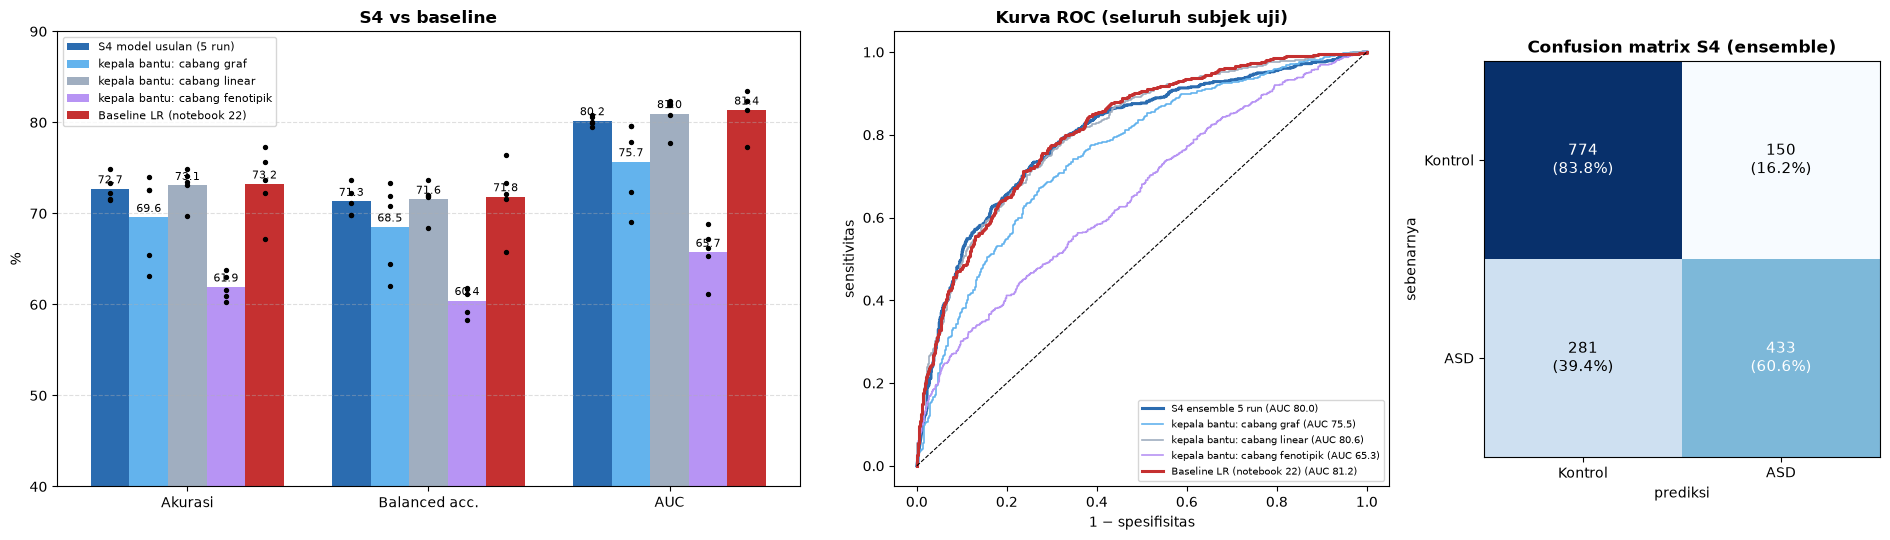

In [15]:
WARNA = {"S4 model usulan (5 run)": "#2B6CB0", "  kepala bantu: cabang graf": "#63B3ED", "  kepala bantu: cabang linear": "#A0AEC0", "  kepala bantu: cabang fenotipik": "#B794F4",
         "Baseline LR (notebook 22)": "#C53030"}
metrik_plot = [("accuracy", "Akurasi"), ("balanced", "Balanced acc."), ("auc", "AUC")]
titik = {"S4 model usulan (5 run)": [[rata_fold(HASIL["p_run"][:, r])[m] for r in range(N_RUN)] for m, _ in metrik_plot]}
for n in ("  kepala bantu: cabang graf", "  kepala bantu: cabang linear", "  kepala bantu: cabang fenotipik", "Baseline LR (notebook 22)"):
    df = metrik_per_fold(PRED[n])
    titik[n] = [list(df[m] * 100) for m, _ in metrik_plot]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
lebar = 0.8 / len(titik)
for j, (n, nilai) in enumerate(titik.items()):
    x = np.arange(len(metrik_plot)) + (j - (len(titik) - 1) / 2) * lebar
    rata = [np.mean(v) for v in nilai]
    axes[0].bar(x, rata, lebar, color=WARNA[n], label=n.strip())
    for xi, v in zip(x, nilai):
        axes[0].scatter(np.full(len(v), xi), v, color="black", s=8, zorder=3)
    for xi, r in zip(x, rata):
        axes[0].text(xi, max(r, 40) + 0.6, f"{r:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(range(len(metrik_plot))); axes[0].set_xticklabels([t for _, t in metrik_plot])
axes[0].set_ylim(40, 90); axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("S4 vs baseline", fontweight="bold"); axes[0].grid(axis="y", alpha=0.4, ls="--")

WARNA_ROC = {"S4 ensemble 5 run": "#2B6CB0", **{k: v for k, v in WARNA.items() if k != "S4 model usulan (5 run)"}}
for n, p in PRED.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, color=WARNA_ROC[n], lw=2.2 if n.startswith("S4") or n.startswith("Baseline") else 1.2,
                 label=f"{n.strip()} (AUC {hitung_metrik(y, p)['auc'] * 100:.1f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("1 − spesifisitas"); axes[1].set_ylabel("sensitivitas"); axes[1].legend(fontsize=7.5, loc="lower right")
axes[1].set_title("Kurva ROC (seluruh subjek uji)", fontweight="bold")

cm = confusion_matrix(y, (HASIL["p"] >= 0.5).astype(int))
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Kontrol", "ASD"]); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["Kontrol", "ASD"])
axes[2].set_xlabel("prediksi"); axes[2].set_ylabel("sebenarnya"); axes[2].set_title("Confusion matrix S4 (ensemble)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "29_3_hasil_s4.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.6 Akurasi per dataset dan per situs

,Subjek,Akurasi S4 ensemble (%),Akurasi LR (%)
ABIDE I,886,72.800000,73.360000
ABIDE II,752,74.730000,73.140000


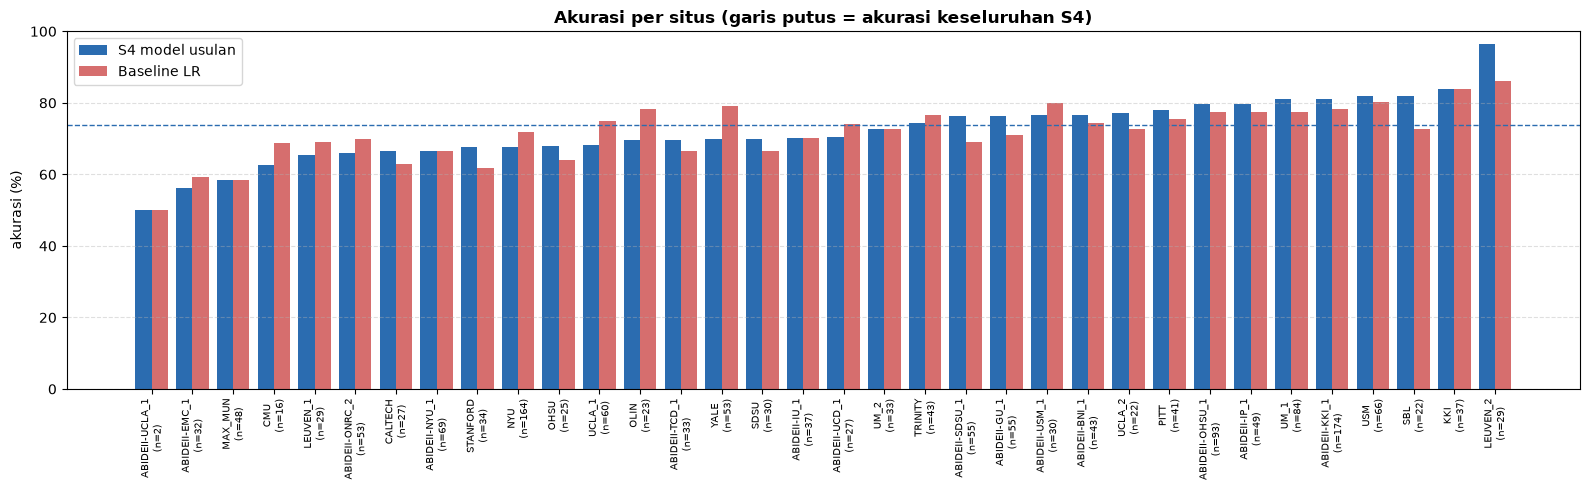

In [16]:
benar = lambda p: ((p >= 0.5).astype(int) == y)
per_ds = pd.DataFrame({"Subjek": pd.Series(dataset).value_counts(),
                       "Akurasi S4 ensemble (%)": pd.Series(benar(HASIL["p"])).groupby(dataset).mean() * 100,
                       "Akurasi LR (%)": pd.Series(benar(P_LR)).groupby(dataset).mean() * 100})
per_ds.index = per_ds.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II"})
display(per_ds.round(2).style.set_caption("Akurasi per dataset"))

per_situs = (pd.DataFrame({"situs": situs, "S4": benar(HASIL["p"]), "LR": benar(P_LR)})
             .groupby("situs").agg(n=("S4", "size"), S4=("S4", "mean"), LR=("LR", "mean")).sort_values("S4"))
per_situs[["S4", "LR"]] *= 100
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(per_situs))
ax.bar(x - 0.2, per_situs["S4"], 0.4, color="#2B6CB0", label="S4 model usulan")
ax.bar(x + 0.2, per_situs["LR"], 0.4, color="#C53030", alpha=0.7, label="Baseline LR")
ax.axhline(benar(HASIL["p"]).mean() * 100, color="#2B6CB0", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(per_situs.index, per_situs["n"])], rotation=90, fontsize=7.5)
ax.set_ylabel("akurasi (%)"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", alpha=0.4, ls="--")
ax.set_title("Akurasi per situs (garis putus = akurasi keseluruhan S4)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "29_4_akurasi_per_situs_s4.png", dpi=150, bbox_inches="tight")
plt.show()
per_situs.round(2).to_csv(TABEL_DIR / "29_S4_per_situs.csv")

### 7.7 Kurva belajar pelatihan akhir

Loss latih dan AUC validasi setiap epoch, untuk 5 fold × 5 run. Titik merah adalah epoch yang bobotnya dipakai.

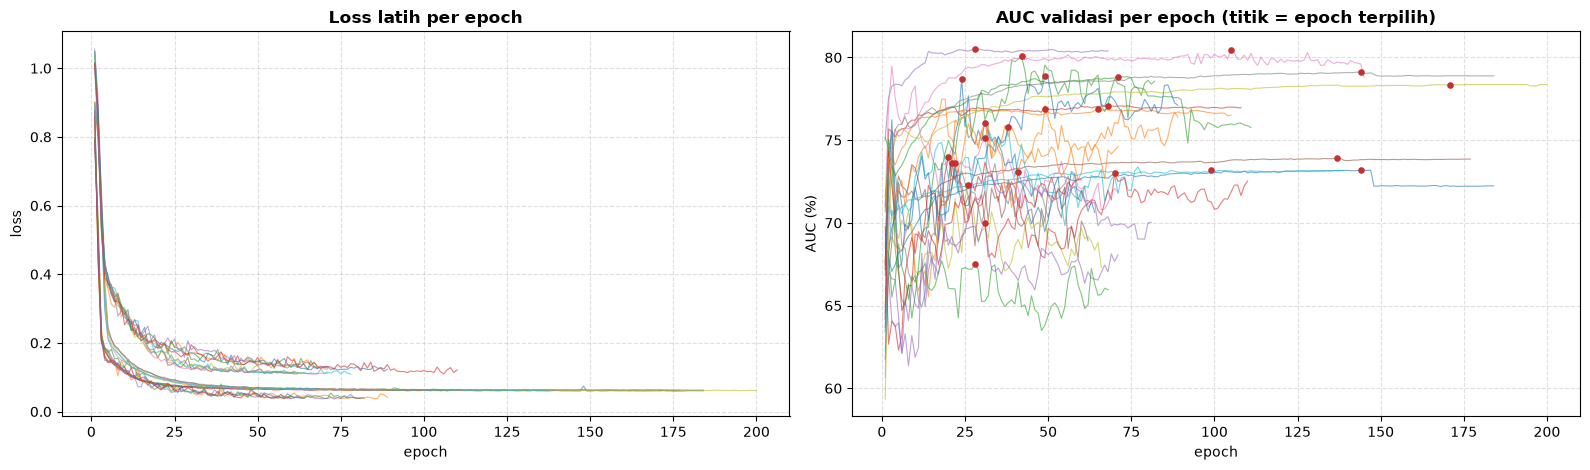

,fold,seed,epoch_terbaik,auc_val,detik,riwayat_pralatih
0,0,0,144,0.732000,452.128000,[]
1,0,1,65,0.769000,263.147000,[]
2,0,2,71,0.788000,278.078000,[]
3,0,3,68,0.771000,272.864000,[]
4,0,4,28,0.805000,171.801000,[]
5,1,0,22,0.736000,187.091000,[]
6,1,1,31,0.751000,214.026000,[]
7,1,2,21,0.736000,188.296000,[]
8,1,3,26,0.723000,205.396000,[]
9,1,4,38,0.758000,240.030000,[]


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for l in HASIL["log"]:
    r = l["riwayat"]
    axes[0].plot(r[:, 0], r[:, 1], lw=0.8, alpha=0.6)
    axes[1].plot(r[:, 0], r[:, 2] * 100, lw=0.8, alpha=0.6)
    axes[1].scatter(l["epoch_terbaik"], l["auc_val"] * 100, color="#C53030", s=14, zorder=3)
axes[0].set_title("Loss latih per epoch", fontweight="bold"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("AUC validasi per epoch (titik = epoch terpilih)", fontweight="bold"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC (%)")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "29_5_kurva_belajar_s4.png", dpi=150, bbox_inches="tight")
plt.show()
log_df = pd.DataFrame([{k: v for k, v in l.items() if k != "riwayat"} for l in HASIL["log"]])
display(log_df.round(3).style.set_caption("Ringkasan setiap seed"))
log_df.to_csv(TABEL_DIR / "29_S4_log_seed.csv", index=False)

### 7.8 Pemilihan metode usulan: S1–S4

Aturan pemilihan sama dengan sebelumnya: **AUC validasi tertinggi** (rata-rata AUC validasi 25 pelatihan, 5 fold × 5 seed). Akurasi dan AUC uji ditampilkan di sebelahnya sebagai pembanding.

> **Catatan penting:** hyperparameter S4 dipilih memakai AUC validasi, sedangkan S1–S3 tidak. Karena itu AUC validasi S4 cenderung lebih tinggi daripada aslinya. Kalau S4 menang hanya di AUC validasi tetapi tidak di data uji, kemenangan itu sebaiknya **tidak** dianggap bukti bahwa S4 lebih baik.

In [18]:
SUMBER = {"S1": ("25_S1", "S1"), "S2": ("26_S2", "S2"), "S3": ("27_S3", "S3")}
baris = []
for nama, (awalan, kunci) in SUMBER.items():
    r = json.load(open(METRIK_DIR / f"{kunci}_ringkasan.json", encoding="utf-8"))
    baris.append({"Konfigurasi": nama, "AUC validasi (%)": pd.read_csv(TABEL_DIR / f"{awalan}_log_seed.csv")["auc_val"].mean() * 100,
                  "Akurasi uji per run (%)": r["rata_rata_antar_run"]["Akurasi (%)"], "AUC uji per run (%)": r["rata_rata_antar_run"]["AUC (%)"],
                  "Akurasi uji ensemble (%)": r["ensemble"]["accuracy"], "AUC uji ensemble (%)": r["ensemble"]["auc"]})
baris.append({"Konfigurasi": "S4 (S3 + Optuna)", "AUC validasi (%)": log_df["auc_val"].mean() * 100,
              "Akurasi uji per run (%)": tab_run.mean()["Akurasi (%)"], "AUC uji per run (%)": tab_run.mean()["AUC (%)"],
              "Akurasi uji ensemble (%)": rata_fold(HASIL["p"])["accuracy"], "AUC uji ensemble (%)": rata_fold(HASIL["p"])["auc"]})
pilih = pd.DataFrame(baris).set_index("Konfigurasi")
pilih["Metode usulan"] = np.where(pilih.index == pilih["AUC validasi (%)"].idxmax(), "◄ AUC validasi tertinggi", "")
display(pilih.round(2).style.set_caption("Pemilihan metode usulan (S1–S4)"))
pilih.round(4).to_csv(TABEL_DIR / "29_pemilihan_metode_usulan.csv")

,AUC validasi (%),Akurasi uji per run (%),AUC uji per run (%),Akurasi uji ensemble (%),AUC uji ensemble (%),Metode usulan
Konfigurasi,,,,,,
S1,74.050000,70.540000,78.000000,72.450000,79.220000,
S2,74.010000,70.950000,77.780000,73.070000,79.290000,
S3,74.590000,71.780000,79.400000,73.370000,81.230000,
S4 (S3 + Optuna),75.600000,72.700000,80.190000,73.680000,81.120000,◄ AUC validasi tertinggi


### 7.9 Interpretasi: bobot cabang (β) dan parcel terpenting (α)

Sama dengan S3: β = seberapa besar model mengandalkan setiap cabang (garis putus = 1/3), α = bobot setiap parcel dalam ringkasan graf (rata-rata 1/360). Dihitung pada subjek uji setiap fold (rata-rata 5 run).

,Parcel HCP,α rata-rata (×1000),α ASD (×1000),α Kontrol (×1000),Kali dari rata-rata
0,R_MBelt_ROI,3.786000,3.820000,3.759000,1.363000
1,L_a24_ROI,3.598000,3.585000,3.607000,1.295000
2,L_1_ROI,3.553000,3.425000,3.652000,1.279000
3,R_V6_ROI,3.373000,3.368000,3.376000,1.214000
4,L_FOP2_ROI,3.336000,3.352000,3.323000,1.201000
5,R_d32_ROI,3.326000,3.368000,3.294000,1.197000
6,L_VMV1_ROI,3.320000,3.298000,3.337000,1.195000
7,R_PBelt_ROI,3.282000,3.252000,3.304000,1.181000
8,R_ProS_ROI,3.258000,3.276000,3.244000,1.173000
9,L_10v_ROI,3.237000,3.261000,3.218000,1.165000


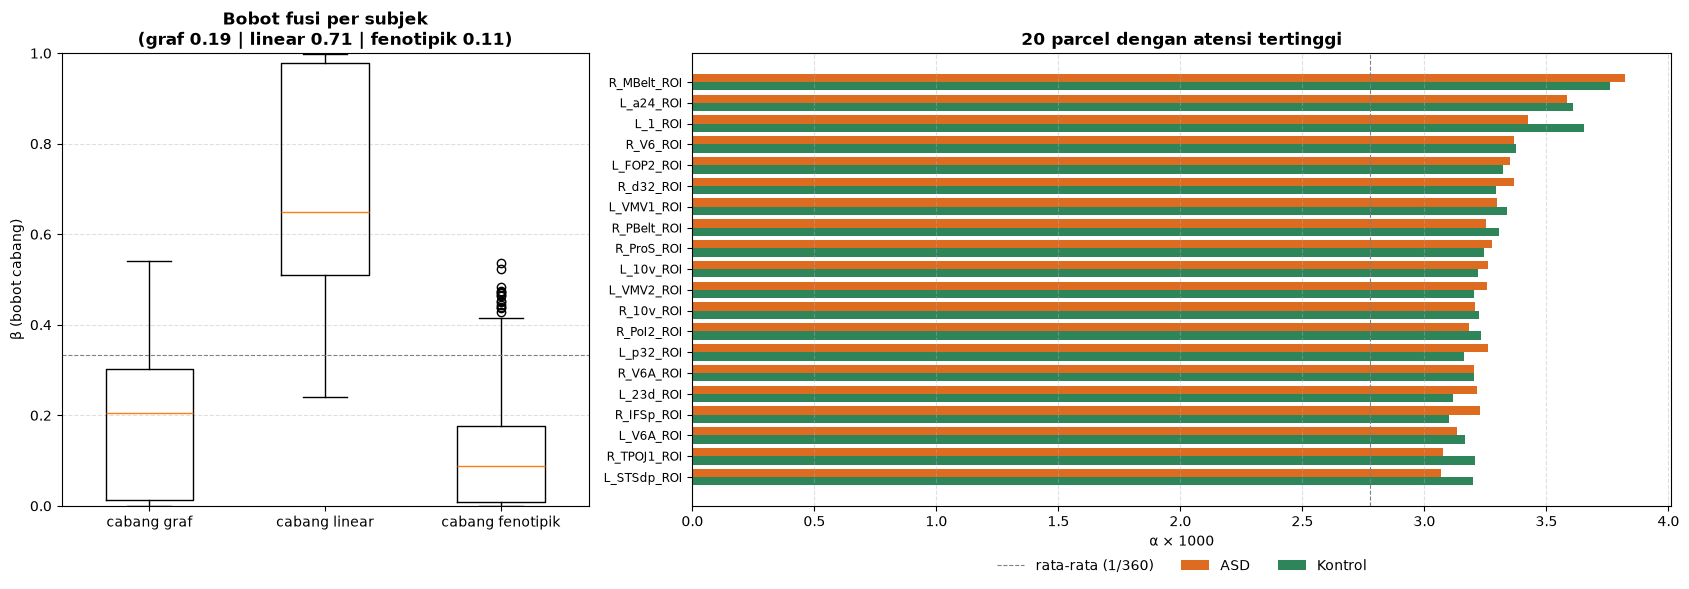

: 

In [ ]:
beta = pd.DataFrame(HASIL["beta"], columns=["graf", "linear", "fenotipik"])
alpha = HASIL["alpha"]
rata_alpha = alpha.mean(0)
top = np.argsort(rata_alpha)[::-1][:20]
tab_roi = pd.DataFrame({"Parcel HCP": NAMA_PARCEL[top], "α rata-rata (×1000)": rata_alpha[top] * 1000,
                        "α ASD (×1000)": alpha[y == 1][:, top].mean(0) * 1000, "α Kontrol (×1000)": alpha[y == 0][:, top].mean(0) * 1000,
                        "Kali dari rata-rata": rata_alpha[top] * N_SIMPUL})
display(tab_roi.round(3).reset_index(drop=True).style.set_caption("20 parcel dengan bobot atensi tertinggi"))
tab_roi.to_csv(TABEL_DIR / "29_S4_parcel_atensi_tertinggi.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [0.7, 1.3]})
axes[0].boxplot([beta["graf"], beta["linear"], beta["fenotipik"]], tick_labels=["cabang graf", "cabang linear", "cabang fenotipik"], widths=0.5)
axes[0].axhline(1 / 3, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("β (bobot cabang)"); axes[0].set_ylim(0, 1)
axes[0].set_title(f"Bobot fusi per subjek\n(graf {beta['graf'].mean():.2f} | linear {beta['linear'].mean():.2f} | fenotipik {beta['fenotipik'].mean():.2f})", fontweight="bold")
yy = np.arange(len(top))[::-1]
axes[1].barh(yy + 0.2, tab_roi["α ASD (×1000)"], 0.4, color="#DD6B20", label="ASD")
axes[1].barh(yy - 0.2, tab_roi["α Kontrol (×1000)"], 0.4, color="#2F855A", label="Kontrol")
axes[1].axvline(1000 / N_SIMPUL, color="gray", ls="--", lw=0.8, label="rata-rata (1/360)")
axes[1].set_yticks(yy); axes[1].set_yticklabels(tab_roi["Parcel HCP"], fontsize=8.5)
axes[1].set_xlabel("α × 1000"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False); axes[1].set_title("20 parcel dengan atensi tertinggi", fontweight="bold")
for ax in axes:
    ax.grid(axis="x" if ax is axes[1] else "y", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "29_6_interpretasi_atensi_s4.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Cara Membaca Hasil

| Pertanyaan | Dilihat dari |
| :--- | :--- |
| Apakah Optuna menemukan pengaturan yang lebih baik daripada S3 di validasi-tuning? | tabel dan grafik 5.1 (AUC val S3 vs terbaik, trial terbaik ≠ 0) |
| Apakah pengaturan setiap fold mirip atau berbeda jauh? | tabel 5.1: pengaturan yang mirip antar fold berarti hasil pencarian stabil |
| Seberapa baik S4 di data uji? | baris **Rata-rata ± SD antar run** di tabel 7.1 |
| **Apakah S4 lebih baik daripada S3?** | **7.4**: selisih per run, uji t berpasangan, McNemar S3 vs S4 |
| Apakah setara, lebih baik, atau lebih rendah dari LR? | tabel 7.3 (kolom **p Holm**) |
| Apakah S4 overfitting ke validasi-tuning? | AUC validasi naik (5.1) tetapi akurasi/AUC uji tidak naik (7.4) |
| Metode usulan mana? | tabel 7.8, dengan memperhatikan catatan di atasnya |

### Kesimpulan

*(Diisi setelah melihat hasil.)*